# Optimization and Regularization on MNIST

Compare gradient-descent batch sizes, investigate dropout, and implement validation-based checkpointing and early stopping.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

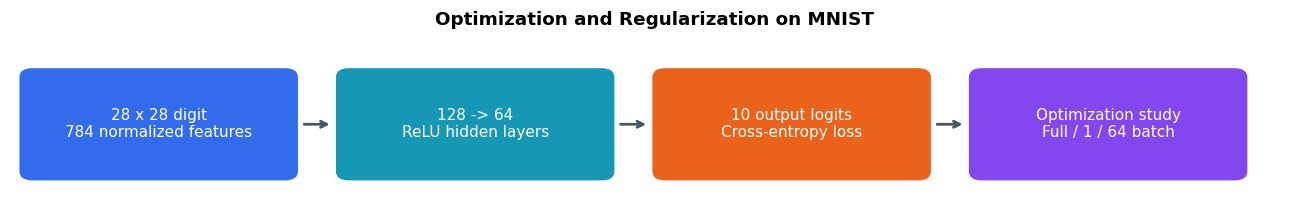

In [2]:
show_architecture(['28 x 28 digit\n784 normalized features', '128 -> 64\nReLU hidden layers', '10 output logits\nCross-entropy loss', 'Optimization study\nFull / 1 / 64 batch'], 'Optimization and Regularization on MNIST')

In [3]:
# Import libraries and set reproducibility.
from pathlib import Path
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.set_num_threads(1)
DEVICE = torch.device("cpu")  # Small single-sample updates avoid GPU launch overhead.
print("Device:", DEVICE)

OUTPUT_DIR = Path("artifacts/optimization_regularization")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


Device: cpu


In [4]:
# Read the attached MNIST files without a network download.
from pathlib import Path
import shutil
raw_dir = Path('./data/mnist/MNIST/raw')
raw_dir.mkdir(parents=True, exist_ok=True)
for filename in ['train-images-idx3-ubyte', 'train-labels-idx1-ubyte',
                 't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte']:
    matches = [p for p in Path('/kaggle/input').rglob(filename) if p.is_file()]
    if not matches:
        raise FileNotFoundError(f'Missing attached MNIST file: {filename}')
    shutil.copy2(matches[0], raw_dir / filename)
# Load and normalize MNIST; keep images as tensors for custom batching.
train_ds = datasets.MNIST(root="./data/mnist", train=True, download=False)
test_ds = datasets.MNIST(root="./data/mnist", train=False, download=False)

X_train = train_ds.data.float().div(255.0).view(-1, 784)
y_train = train_ds.targets.long()

X_test = test_ds.data.float().div(255.0).view(-1, 784)
y_test = test_ds.targets.long()

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train: torch.Size([60000, 784]) torch.Size([60000])
Test : torch.Size([10000, 784]) torch.Size([10000])


### MNIST examples

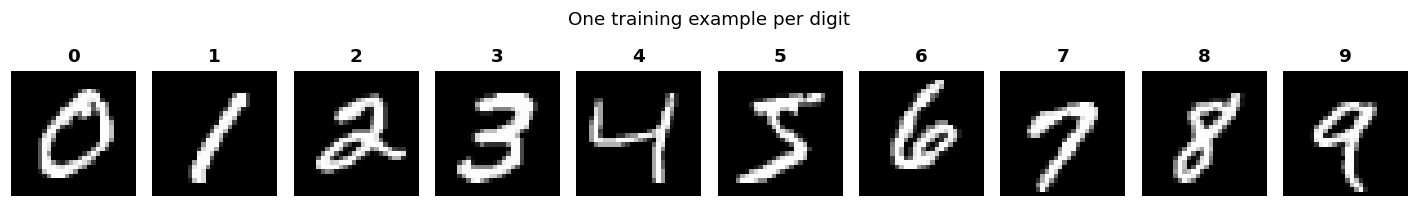

In [5]:
fig, axes=plt.subplots(1,10,figsize=(13,2))
for digit,ax in enumerate(axes):
    index=int(torch.nonzero(y_train==digit)[0])
    ax.imshow(X_train[index].reshape(28,28),cmap='gray'); ax.set_title(str(digit)); ax.axis('off')
fig.suptitle('One training example per digit'); plt.tight_layout(); plt.show()

In [6]:
# Custom batch generator used by all experiments.
def batch_loader(X, y, batch_size, shuffle=True):
    n = len(X)
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        ids = idx[start:start + batch_size]
        yield X[ids].to(DEVICE), y[ids].to(DEVICE)

@torch.no_grad()
def evaluation_loss(model, X, y, batch_size=512):
    """Sample-weighted loss with dropout disabled and bounded evaluation memory."""
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total = 0.0
    for xb, yb in batch_loader(X, y, batch_size, shuffle=False):
        total += criterion(model(xb), yb).item() * len(yb)
    return total / len(y)


In [7]:
# Define the Task 1 feedforward neural network.
class FNN(nn.Module):
    def __init__(self, dropout=0.0, hidden=512, layers=4):
        super().__init__()
        modules = [nn.Linear(784, hidden), nn.ReLU()]
        for _ in range(layers - 1):
            modules += [nn.Dropout(dropout), nn.Linear(hidden, hidden), nn.ReLU()]
        modules += [nn.Dropout(dropout), nn.Linear(hidden, 10)]
        self.net = nn.Sequential(*modules)

    def forward(self, x):
        return self.net(x)

def task1_model():
    return nn.Sequential(
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    ).to(DEVICE)

def task2_model(dropout):
    return FNN(dropout=dropout, hidden=512, layers=4).to(DEVICE)

In [8]:
# Generic training loop that records loss and epoch time.
def train_epochs(model, X, y, epochs, batch_size, lr=0.01, val_data=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_eval_loss": [], "val_loss": [], "epoch_time": []}

    for epoch in range(epochs):
        synchronize_device()
        start = time.perf_counter()
        model.train()
        total_loss = 0.0
        total_n = 0

        for xb, yb in batch_loader(X, y, batch_size, shuffle=True):
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            total_n += len(yb)

        train_loss = total_loss / total_n
        history["train_loss"].append(train_loss)

        if val_data is not None:
            Xv, yv = val_data
            history["train_eval_loss"].append(evaluation_loss(model, X, y))
            val_loss = evaluation_loss(model, Xv, yv)
            history["val_loss"].append(val_loss)

        synchronize_device()
        history["epoch_time"].append(time.perf_counter() - start)
        print(f"Epoch {epoch+1:3d}/{epochs} | loss={train_loss:.4f} | "
              f"time={history['epoch_time'][-1]:.2f}s" +
              (f" | val_loss={history['val_loss'][-1]:.4f}" if val_data is not None else ""))

    return history

## Optimization comparison — Gradient Descent Variants

The architecture is `784 → 128 → 64 → 10`.  
The only experimental variable is batch size: full training set, 1, or 64.  
Learning rate is fixed at `0.01` and training runs for 20 epochs.

All runs start from the same initial weights and shuffled-data seed. One epoch contains one update for BGD, 60,000 for SGD, and approximately 938 for mini-batch GD; equal epochs therefore do not mean equal optimizer steps. The plotted loss averages predictions made during the epoch, while weights are changing.

In [9]:
# Train the same architecture with BGD, SGD, and mini-batch GD.
EPOCHS = 20
LR = 0.01

task1_results = {}

configs = {
    "BGD": len(X_train),
    "SGD": 1,
    "Mini-batch": 64
}

for name, batch_size in configs.items():
    print("\n" + "=" * 60)
    print(name, "batch_size =", batch_size)
    reset_seed()
    model = task1_model()
    task1_results[name] = train_epochs(
        model, X_train, y_train, epochs=EPOCHS,
        batch_size=batch_size, lr=LR
    )


BGD batch_size = 60000


Epoch   1/20 | loss=2.3139 | time=0.90s


Epoch   2/20 | loss=2.3135 | time=0.77s


Epoch   3/20 | loss=2.3130 | time=0.72s


Epoch   4/20 | loss=2.3126 | time=0.71s


...

Epoch  16/20 | loss=0.1716 | time=1.33s


Epoch  17/20 | loss=0.1643 | time=1.31s


Epoch  18/20 | loss=0.1573 | time=1.31s


Epoch  19/20 | loss=0.1505 | time=1.31s


Epoch  20/20 | loss=0.1445 | time=1.26s


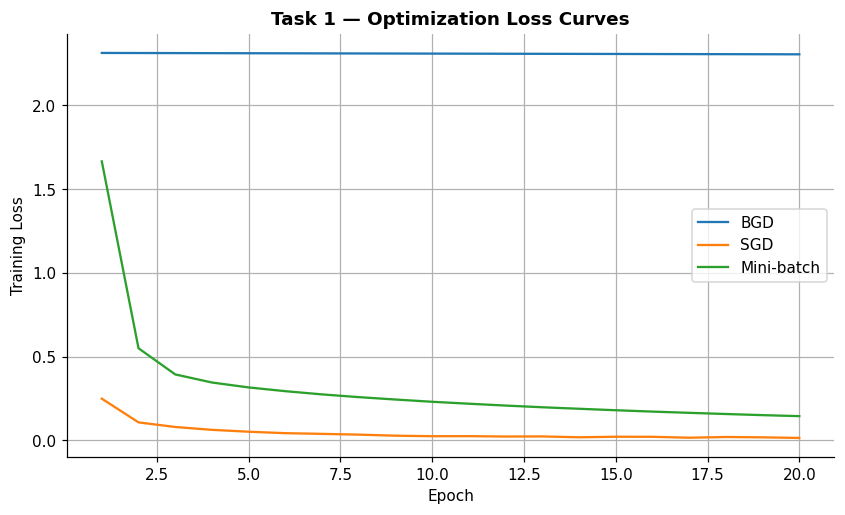

,Final loss,Mean epoch time (s),Total training time (s)
BGD,2.305728,0.741703,14.834054
SGD,0.014304,38.298245,765.964894
Mini-batch,0.144471,1.337429,26.748589


In [10]:
# Plot Task 1 loss curves and compare convergence stability visually.
plt.figure(figsize=(9, 5))
for name, h in task1_results.items():
    plt.plot(range(1, EPOCHS + 1), h["train_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Task 1 — Optimization Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

summary = pd.DataFrame({
    name: {
        "Final loss": h["train_loss"][-1],
        "Mean epoch time (s)": np.mean(h["epoch_time"]),
        "Total training time (s)": np.sum(h["epoch_time"])
    }
    for name, h in task1_results.items()
}).T
display(summary)

### Computational cost

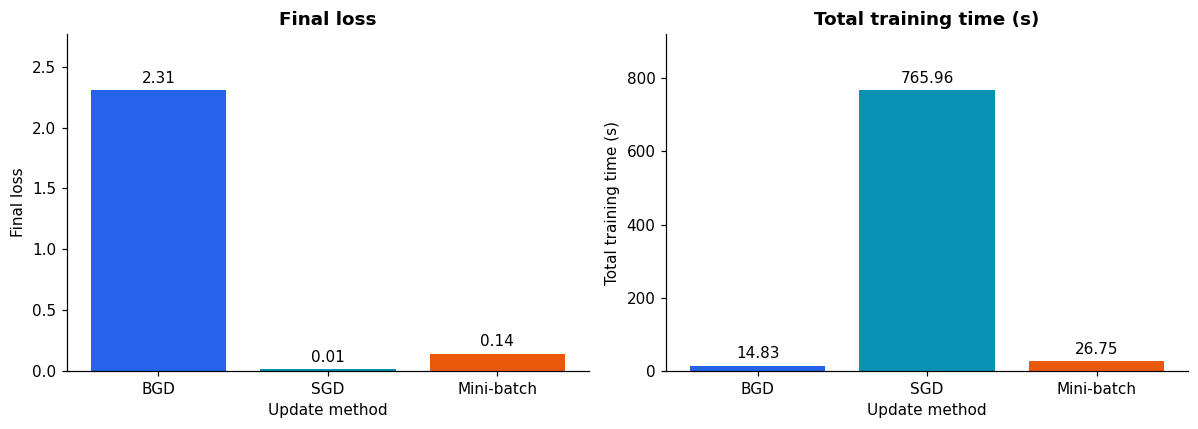

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,column in zip(axes,['Final loss','Total training time (s)']):
    bars=ax.bar(summary.index,summary[column],color=PALETTE[:3]); ax.bar_label(bars,fmt='%.2f',padding=3)
    ax.set(title=column,xlabel='Update method',ylabel=column); ax.set_ylim(0,summary[column].max()*1.2)
plt.tight_layout(); plt.show()

## Regularization comparison — Dropout Regularization

To intentionally encourage overfitting, use a larger `4 × 512` hidden-layer network and only 5,000 training examples.

A separate 5,000-example validation split is taken from the original MNIST training set. The official 10,000-example MNIST test set is kept untouched for final evaluation.

In [12]:
# Create the 5,000-sample training split and 5,000-sample validation split.
perm = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(SEED))
task2_train_idx = perm[:5000]
task2_val_idx = perm[5000:10000]

X_small = X_train[task2_train_idx]
y_small = y_train[task2_train_idx]
X_val = X_train[task2_val_idx]
y_val = y_train[task2_val_idx]

print("Task 2 train:", X_small.shape)
print("Task 2 val  :", X_val.shape)

Task 2 train: torch.Size([5000, 784])
Task 2 val  : torch.Size([5000, 784])


In [13]:
# Train and compare the three dropout configurations.
DROPOUTS = [0.0, 0.2, 0.5]
task2_results = {}

for p in DROPOUTS:
    print("\n" + "=" * 60)
    print(f"Dropout p = {p}")
    reset_seed()
    model = task2_model(p)
    task2_results[p] = train_epochs(
        model, X_small, y_small, epochs=30,
        batch_size=64, lr=0.01,
        val_data=(X_val, y_val)
    )


Dropout p = 0.0


Epoch   1/30 | loss=2.3024 | time=1.25s | val_loss=2.3009


Epoch   2/30 | loss=2.3006 | time=1.20s | val_loss=2.2995


Epoch   3/30 | loss=2.2989 | time=1.11s | val_loss=2.2982


Epoch   4/30 | loss=2.2971 | time=1.13s | val_loss=2.2967


...

Epoch  26/30 | loss=2.1362 | time=1.36s | val_loss=2.0869


Epoch  27/30 | loss=2.0952 | time=1.34s | val_loss=2.0343


Epoch  28/30 | loss=2.0511 | time=1.39s | val_loss=1.9809


Epoch  29/30 | loss=2.0045 | time=1.39s | val_loss=1.9231


Epoch  30/30 | loss=1.9519 | time=1.36s | val_loss=1.8550


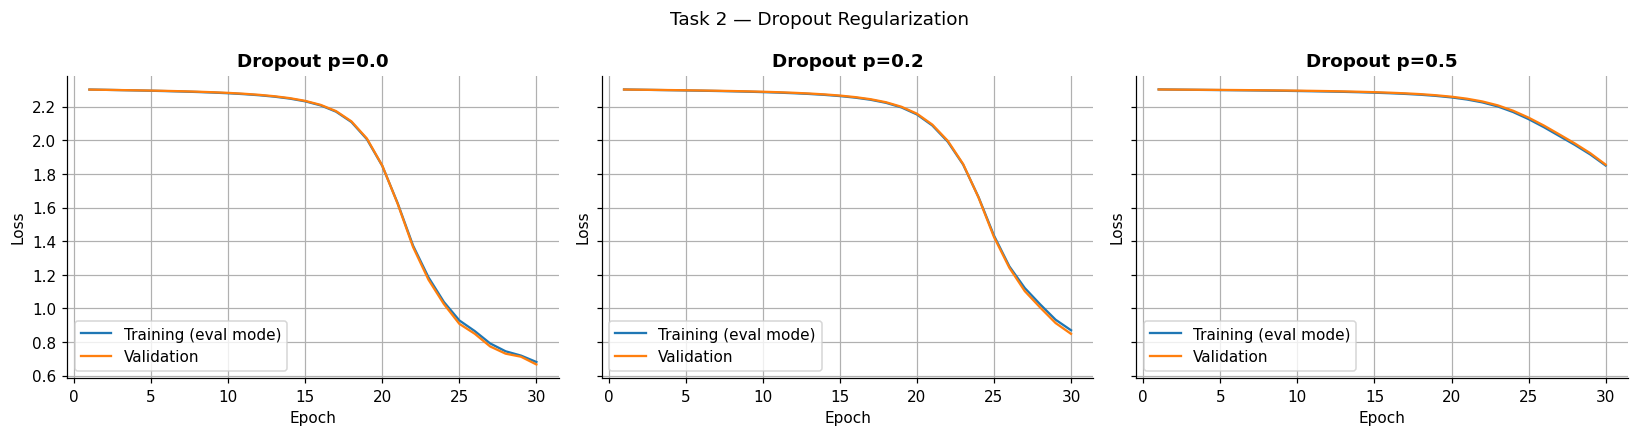

In [14]:
# Plot training and validation loss for all dropout settings.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, DROPOUTS):
    h = task2_results[p]
    epochs = range(1, len(h["train_loss"]) + 1)
    ax.plot(epochs, h["train_eval_loss"], label="Training (eval mode)")
    ax.plot(epochs, h["val_loss"], label="Validation")
    ax.set_title(f"Dropout p={p}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

plt.suptitle("Task 2 — Dropout Regularization")
plt.tight_layout()
plt.show()

In [15]:
# Compare final validation loss and the generalization gap.
dropout_summary = pd.DataFrame({
    f"p={p}": {
        "Final training loss (eval mode)": task2_results[p]["train_eval_loss"][-1],
        "Final validation loss": task2_results[p]["val_loss"][-1],
        "Generalization gap": task2_results[p]["val_loss"][-1] - task2_results[p]["train_eval_loss"][-1]
    }
    for p in DROPOUTS
}).T
display(dropout_summary)

,Final training loss (eval mode),Final validation loss,Generalization gap
p=0.0,0.682073,0.667409,-0.014664
p=0.2,0.870669,0.849190,-0.021479
p=0.5,1.849609,1.855047,0.005437


## Early stopping — Custom Early Stopping

Use the `p=0.2` architecture for up to 100 epochs.

Rules:
- `patience = 5`
- `min_delta = 0.001`
- Save weights at the lowest observed validation loss. Use meaningful improvement to reset patience.
- Stop after 5 consecutive non-improving epochs.
- Restore the best weights before final testing.

In [16]:
class EarlyStopping:
    """Separate the best checkpoint from the meaningful-improvement patience rule."""
    def __init__(self, patience=5, min_delta=0.001, path=None):
        self.patience = patience
        self.min_delta = min_delta
        self.path = Path(path) if path else OUTPUT_DIR / "best_model.pt"
        self.best_loss = float("inf")
        self.reference_loss = float("inf")
        self.wait = 0
        self.best_epoch = 0
        self.stop_epoch = None

    def step(self, val_loss, model, epoch):
        if not np.isfinite(val_loss):
            raise ValueError("Validation loss must be finite.")
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.path.parent.mkdir(parents=True, exist_ok=True)
            torch.save(copy.deepcopy(model.state_dict()), self.path)
        if val_loss < self.reference_loss - self.min_delta:
            self.reference_loss = val_loss
            self.wait = 0
        else:
            self.wait += 1
        if self.wait >= self.patience:
            self.stop_epoch = epoch
            return True
        return False

    def restore_best(self, model):
        model.load_state_dict(torch.load(self.path, map_location=DEVICE, weights_only=True))

In [17]:
# Train the p=0.2 model with the custom early-stopping logic.
def train_with_early_stopping(model, X, y, Xv, yv, max_epochs=100, batch_size=64, lr=0.01):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    stopper = EarlyStopping(patience=5, min_delta=0.001, path=OUTPUT_DIR / "early_stopping_best.pt")
    history = {"train_loss": [], "val_loss": [], "epoch_time": []}

    for epoch in range(max_epochs):
        synchronize_device()
        start = time.perf_counter()
        model.train()
        total_loss, total_n = 0.0, 0

        for xb, yb in batch_loader(X, y, batch_size, shuffle=True):
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            total_n += len(yb)

        train_loss = total_loss / total_n
        val_loss = evaluation_loss(model, Xv, yv)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        synchronize_device()
        history["epoch_time"].append(time.perf_counter() - start)

        epoch_num = epoch + 1
        print(f"Epoch {epoch_num:3d}/{max_epochs} | train={train_loss:.4f} | val={val_loss:.4f}")

        if stopper.step(val_loss, model, epoch_num):
            print(f"Early stopping triggered at epoch {epoch_num}.")
            break

    stopper.restore_best(model)
    return history, stopper

In [18]:
reset_seed()
# Train the early-stopped model.
task3_model = task2_model(0.2)
task3_history, stopper = train_with_early_stopping(
    task3_model, X_small, y_small, X_val, y_val,
    max_epochs=100, batch_size=64, lr=0.01
)

print("Best epoch:", stopper.best_epoch)
print("Stopping epoch:", stopper.stop_epoch)

Epoch   1/100 | train=2.3028 | val=2.3012


Epoch   2/100 | train=2.3013 | val=2.3002


Epoch   3/100 | train=2.3001 | val=2.2992


Epoch   4/100 | train=2.2988 | val=2.2981


Epoch   5/100 | train=2.2975 | val=2.2969


...

Epoch  96/100 | train=0.1626 | val=0.2546


Epoch  97/100 | train=0.1476 | val=0.2549


Epoch  98/100 | train=0.1454 | val=0.2405


Epoch  99/100 | train=0.1442 | val=0.2318


Epoch 100/100 | train=0.1375 | val=0.2381
Best epoch: 99
Stopping epoch: None


In [19]:
reset_seed()
# Train an identical p=0.2 model for the full 100 epochs without early stopping.
full100_model = task2_model(0.2)
full100_history = train_epochs(
    full100_model, X_small, y_small,
    epochs=100, batch_size=64, lr=0.01,
    val_data=(X_val, y_val)
)

Epoch   1/100 | loss=2.3028 | time=1.30s | val_loss=2.3012


Epoch   2/100 | loss=2.3013 | time=1.30s | val_loss=2.3002


Epoch   3/100 | loss=2.3001 | time=1.30s | val_loss=2.2992


Epoch   4/100 | loss=2.2988 | time=1.27s | val_loss=2.2981


Epoch   5/100 | loss=2.2975 | time=1.34s | val_loss=2.2969


...

Epoch  96/100 | loss=0.1626 | time=1.34s | val_loss=0.2546


Epoch  97/100 | loss=0.1476 | time=1.33s | val_loss=0.2549


Epoch  98/100 | loss=0.1454 | time=1.32s | val_loss=0.2405


Epoch  99/100 | loss=0.1442 | time=1.31s | val_loss=0.2318


Epoch 100/100 | loss=0.1375 | time=1.29s | val_loss=0.2381


In [20]:
# Evaluate classification accuracy on the untouched MNIST test set.
def accuracy(model, X, y):
    model.eval()
    correct = 0
    total = len(y)
    with torch.no_grad():
        for xb, yb in batch_loader(X, y, 512, shuffle=False):
            pred = model(xb).argmax(dim=1)
            correct += (pred == yb).sum().item()
    return correct / total

early_test_acc = accuracy(task3_model, X_test, y_test)
full100_test_acc = accuracy(full100_model, X_test, y_test)

print(f"Validation-selected checkpoint test accuracy: {early_test_acc * 100:.2f}%")
print(f"100-epoch test accuracy:      {full100_test_acc * 100:.2f}%")

Validation-selected checkpoint test accuracy: 93.34%
100-epoch test accuracy:      93.33%


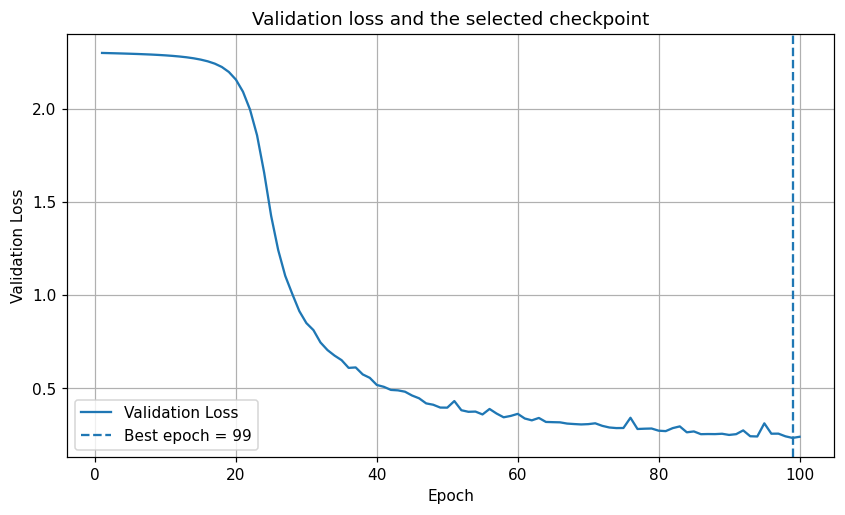

In [21]:
# Plot validation loss and mark both the best and stopping epochs.
plt.figure(figsize=(9, 5))
epochs = range(1, len(task3_history["val_loss"]) + 1)
plt.plot(epochs, task3_history["val_loss"], label="Validation Loss")
plt.axvline(stopper.best_epoch, linestyle="--", label=f"Best epoch = {stopper.best_epoch}")
if stopper.stop_epoch is not None:
    plt.axvline(stopper.stop_epoch, linestyle=":", label=f"Stopping epoch = {stopper.stop_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation loss and the selected checkpoint")
plt.legend()
plt.grid(True)
plt.show()

## Interpretation

**Gradient descent:** SGD has more variability per update because its gradient uses one sample. Mini-batches average several examples while retaining frequent updates. BGD averages the full training set and makes one update per epoch. Epoch-average curves do not directly measure gradient variance. Report measured loss and time; timing includes the operations performed in the loop, including evaluation when configured.

**Dropout:** stochastic masking is active during parameter updates and disabled during evaluation. The plotted dropout comparison evaluates both training and validation loss with masking disabled, so the generalization gap is measured consistently. Lower validation loss is stronger evidence of useful regularization than a small gap alone; a small gap can also indicate underfitting. Batch order and initial weights are seeded equally, but dropout changes subsequent random-number consumption.

**Early stopping:** patience resets when validation loss improves by more than `min_delta`. Independently, the lowest-loss checkpoint is always saved and restored. This avoids calling a slightly worse checkpoint the best merely because the later gain was below `min_delta`. The stopping epoch may be absent if training reaches its epoch limit.

Use the executed tables and plots to compare results. Early stopping and the 100-epoch reference start from matching initial weights and seeds. Model selection uses validation data; test accuracy is measured after training.

The repeated coursework experiment uses one CPU thread throughout so timing comparisons share the same hardware and thread configuration.

## Measured findings

After 20 epochs, full-batch gradient descent reached loss **2.3057** in **14.83 seconds**, SGD reached **0.0143** in **765.96 seconds**, and mini-batch training reached **0.1445** in **26.75 seconds**. Epoch counts do not equalize optimizer updates: full-batch training makes one update per epoch, while SGD makes one per sample. The mini-batch setting offered a practical balance in this experiment.

At 30 epochs, dropout probabilities 0.0, 0.2, and 0.5 gave validation losses **0.6674**, **0.8492**, and **1.8550**. The smallest training–validation gap did not indicate the best model; heavy dropout was still underfitting at this training budget.

Early stopping **did not trigger** within 100 epochs. Restoring the lowest-validation-loss checkpoint at epoch **99** gave **93.34%** test accuracy, compared with **93.33%** for the final 100-epoch reference. This experiment demonstrates checkpoint restoration but provides no evidence of reduced training time from early stopping.